# Early warning: results for the slide deck

Short version of the early-warning results (CV 2024 and holdout 2025-26), all at **15 bp, 2-24 h lead**.
Numbers come from `slides/compute_results.py` (run with the project `.venv`); this notebook only reads
`slides/data/*.csv` and writes the figures to `slides/figures/` (transparent PNG, 300 dpi, legends outside the axes).

**Protocol.** An *event* is a declustered onset of |depeg| >= 15 bp (24 h reset). A warning is *timely* if it comes
2-24 h before onset; alerts are grouped into episodes (12 h cooldown); an alert with no onset in the next 2-24 h is a
false alert. CV: 4 expanding-window folds over 2024, 18 events. Holdout: 2025-01-15 to 2026-05-06, 5 events,
never used for fitting or selection.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
DATA, FIG = Path("data"), Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "legend.frameon": False,
                     "savefig.dpi": 300, "savefig.transparent": True, "savefig.bbox": "tight"})
# fixed colour per model (never by rank); forecast-derived = solid, direct classifiers = dashed
STYLE = {
    "ANGEL exceedance":   dict(color="#2a78d6", ls="-",  lw=3.0),
    "ARIMA":              dict(color="#8e5bd0", ls="-",  lw=2.0),
    "GARCH-t":            dict(color="#eda100", ls="-",  lw=2.0),
    "TiDE forecast":      dict(color="#1baf7a", ls="-",  lw=2.0),
    "TimeXer forecast":   dict(color="#a0522d", ls="-",  lw=2.0),
    "Kumo":               dict(color="#eb6834", ls="--", lw=2.0),
    "TabICL":             dict(color="#c2185b", ls="--", lw=2.0),
    "ANGEL classifier":   dict(color="#2a78d6", ls="--", lw=1.6),
    "|d| now":            dict(color="#555555", ls=":",  lw=2.0),
}
FAMILY_COLOR = {"forecast": "#2a78d6", "classifier": "#eb6834"}
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show()

## 1. Two ways to build a warning score

* **Direct classifier** (benchmark): learn P(onset in 2-24 h | x_t) from the event label. Trees (CatBoost, LightGBM,
  XGBoost, random forest), tabular foundation models (Kumo, TabICL) and sequence classifiers (ANGEL / TiDE / TimeXer /
  iTransformer heads trained on the label).
* **Forecast-derived**: take the probabilistic forecaster as is and read the warning off its predictive distribution,
  S_t = max_{h=2..24} P(|d_{t+h}| >= 15 bp). No extra training on the rare label; the same quantile forecasts as in the
  forecasting section (ANGEL, ARIMA, GARCH-t, TiDE, TimeXer).

## 2. Cost-loss value

A user pays **C** each time they act on a warning (hedge, exit) and loses **L** if an event hits unprotected.
With r = C/L, over N events, D of them caught, and A alert episodes in total:

V(r) = (D - r A) / (N (1 - r))  — the share of the perfect forecaster's saving that the warning system delivers.
V = 1: perfect; V = 0: no better than never acting; V < 0: worse than never acting.

Each cutoff of the score gives one line V(r); the **value envelope** V*(r) takes, for every r, the best cutoff.
**AUVC** = mean of V*(r) over r in [0.01, 0.5]: a threshold-free summary that treats every score identically.

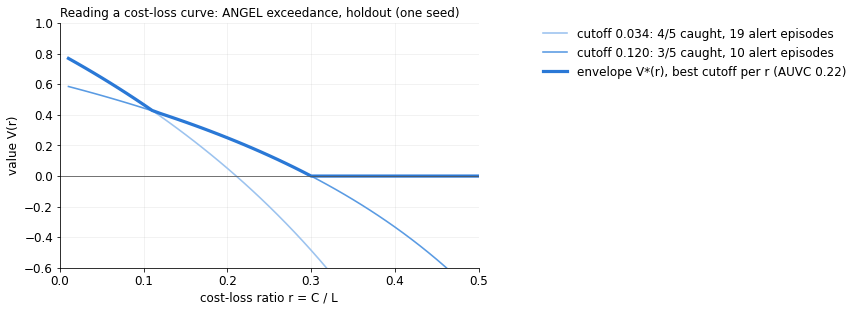

In [2]:
t = pd.read_csv(DATA / "explainer_angel_seed1000_cutoffs.csv")
r = np.round(np.arange(0.01, 0.501, 0.01), 4)
V = np.array([(row.D - r * row.A) / (row.N * (1 - r)) for row in t.itertuples()])      # cutoffs x r
env = np.maximum(V.max(0), 0)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
picks = sorted({int(V[:, list(r).index(x)].argmax()) for x in (0.02, 0.1, 0.3)}, key=lambda i: -t.A[i])
shades = ["#9cc3ef", "#5a9be3", "#1f5fae"]
for k, i in enumerate(picks):
    row = t.iloc[i]
    ax.plot(r, V[i], color=shades[k % 3], lw=1.6,
            label=f"cutoff {row.cutoff:.3f}: {int(row.D)}/{int(row.N)} caught, {int(row.A)} alert episodes")
ax.plot(r, env, color="#2a78d6", lw=3.2, label=f"envelope V*(r), best cutoff per r (AUVC {env.mean():.2f})")
ax.axhline(0, color="#555555", lw=0.8)
ax.set_ylim(-0.6, 1.0); ax.set_xlim(0, 0.5)
ax.set_xlabel("cost-loss ratio r = C / L"); ax.set_ylabel("value V(r)")
ax.set_title("Reading a cost-loss curve: ANGEL exceedance, holdout (one seed)", loc="left", fontsize=12)
fig.legend(loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "01_cost_loss_explainer")

## 3. Forecast-derived scores vs direct classifiers (CV 2024, 18 events)

Bars: AUVC (mean over seeds; whisker = seed sd). Same folds, same events, same scoring for every model.

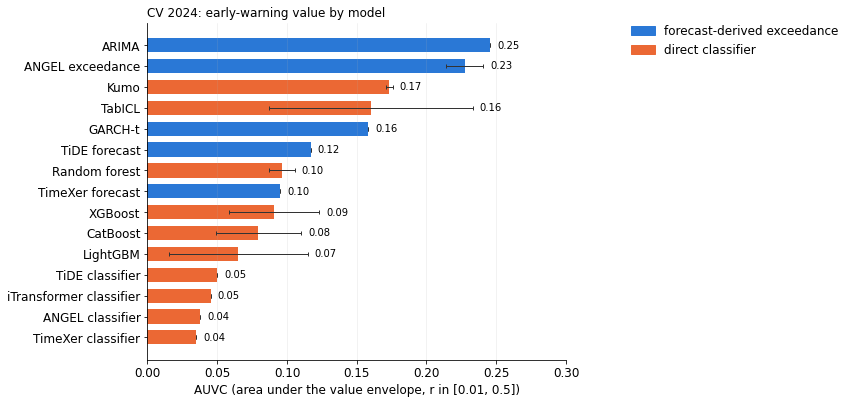

,model,family,n_seeds,AUVC,AUVC_sd,LOFO_min,LOFO_max
1,ARIMA,forecast,1,0.246,NaN,0.206,0.291
0,ANGEL exceedance,forecast,3,0.227,0.013,0.199,0.286
9,Kumo,classifier,3,0.173,0.002,0.144,0.265
10,TabICL,classifier,3,0.160,0.073,0.083,0.336
2,GARCH-t,forecast,1,0.158,NaN,0.158,0.200
3,TiDE forecast,forecast,1,0.117,NaN,0.108,0.149
14,Random forest,classifier,3,0.096,0.009,0.080,0.151
4,TimeXer forecast,forecast,1,0.095,NaN,0.093,0.145
13,XGBoost,classifier,3,0.091,0.033,0.029,0.165
11,CatBoost,classifier,3,0.080,0.030,0.040,0.182


In [3]:
cv = pd.read_csv(DATA / "cv_summary.csv").sort_values("AUVC")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
y = np.arange(len(cv))
ax.barh(y, cv.AUVC, color=[FAMILY_COLOR[f] for f in cv.family], height=0.68, edgecolor="none")
ax.errorbar(cv.AUVC, y, xerr=cv.AUVC_sd.fillna(0), fmt="none", ecolor="#333333", elinewidth=1, capsize=2)
for yi, v, sd in zip(y, cv.AUVC, cv.AUVC_sd.fillna(0)):
    ax.text(v + sd + 0.005, yi, f"{v:.2f}", va="center", fontsize=10)
ax.set_yticks(y); ax.set_yticklabels(cv.model); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUVC (area under the value envelope, r in [0.01, 0.5])"); ax.set_xlim(0, 0.3)
ax.set_title("CV 2024: early-warning value by model", loc="left", fontsize=12)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=FAMILY_COLOR["forecast"], label="forecast-derived exceedance"),
                    Patch(color=FAMILY_COLOR["classifier"], label="direct classifier")],
           loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "02_cv_auvc_forecast_vs_classifier")
cv.sort_values("AUVC", ascending=False)[["model", "family", "n_seeds", "AUVC", "AUVC_sd", "LOFO_min", "LOFO_max"]].round(3)

## 4. Cost-loss curves (without the current-deviation baseline)

CV: one validation quantile applied per fold (scale-free across refits); shaded = range over ANGEL seeds.
Holdout: cutoff on the score itself; ANGEL = mean of the 6 seeds' curves.

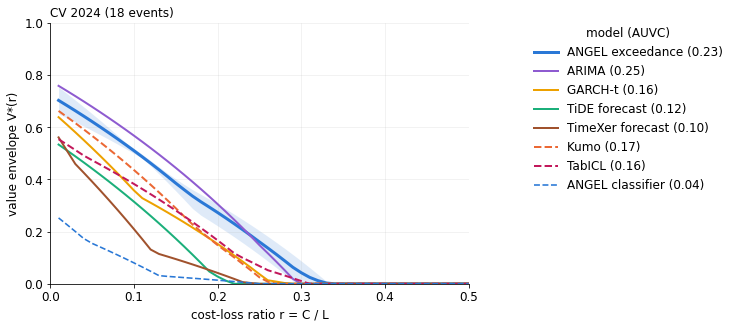

In [4]:
CV_SHOW = ["ANGEL exceedance", "ARIMA", "GARCH-t", "TiDE forecast", "TimeXer forecast", "Kumo", "TabICL", "ANGEL classifier"]
cc = pd.read_csv(DATA / "cv_curves.csv"); cs = pd.read_csv(DATA / "cv_summary.csv").set_index("model")
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for m in CV_SHOW:
    g = cc[cc.model.eq(m)]
    ax.plot(g.r, g.V, label=f"{m} ({cs.loc[m, 'AUVC']:.2f})", **STYLE[m])
    if m == "ANGEL exceedance":
        ax.fill_between(g.r, g.V_min, g.V_max, color=STYLE[m]["color"], alpha=0.15, lw=0)
ax.set_xlim(0, 0.5); ax.set_ylim(0, 1)
ax.set_xlabel("cost-loss ratio r = C / L"); ax.set_ylabel("value envelope V*(r)")
ax.set_title("CV 2024 (18 events)", loc="left", fontsize=12)
fig.legend(title="model (AUVC)", loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "03_cv_value_curves")

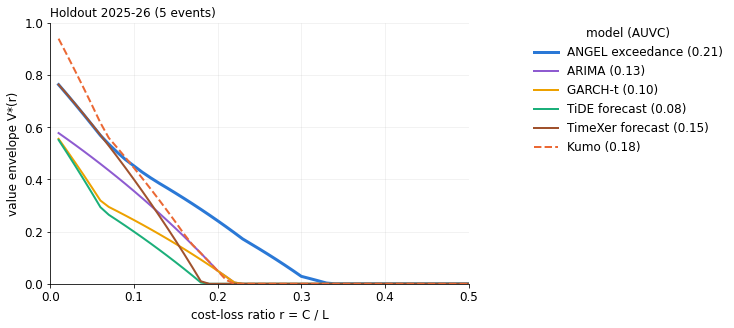

,family,n_seeds,AUVC,AUVC_lead
model,,,,
ANGEL exceedance,forecast,6,0.212,0.070
Kumo,classifier,1,0.178,0.128
TimeXer forecast,forecast,1,0.147,0.073
|d| now,naive,1,0.145,0.057
ARIMA,forecast,1,0.133,0.054
GARCH-t,forecast,1,0.103,0.063
TiDE forecast,forecast,1,0.084,0.062


In [5]:
HO_SHOW = ["ANGEL exceedance", "ARIMA", "GARCH-t", "TiDE forecast", "TimeXer forecast", "Kumo"]
hc = pd.read_csv(DATA / "holdout_curves.csv"); hs = pd.read_csv(DATA / "holdout_summary.csv").set_index("model")
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for m in HO_SHOW:
    g = hc[hc.model.eq(m) & hc.kind.eq("standard")]
    ax.plot(g.r, g.V, label=f"{m} ({hs.loc[m, 'AUVC']:.2f})", **STYLE[m])
ax.set_xlim(0, 0.5); ax.set_ylim(0, 1)
ax.set_xlabel("cost-loss ratio r = C / L"); ax.set_ylabel("value envelope V*(r)")
ax.set_title("Holdout 2025-26 (5 events)", loc="left", fontsize=12)
fig.legend(title="model (AUVC)", loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "04_holdout_value_curves")
hs[["family", "n_seeds", "AUVC", "AUVC_lead"]].sort_values("AUVC", ascending=False).round(3)

## 5. Cost-loss is a simplification: lead time

Standard V(r) counts a caught event as fully avoided, whether the warning came 23 h or 2 h before onset and whether
the price had already drifted to 14 bp. A **lead-time-aware** version measures the loss avoided by a warning at t_a
as the part of the move still ahead:

L_e(t_a) = max_{onset <= t <= onset + 24 h} |d_t| - |d_{t_a}|  (bp, >= 0),

with the perfect warning at the earliest admissible time (24 h before onset) and C = r x (mean perfect L_e):

V_lead(r) = (sum over caught events of L_e(t_a) - C A) / (sum over events of L_e(perfect) - C N).

It equals V(r) when every warning avoids the same loss. Ex post, holdout only (5 events): illustrative.

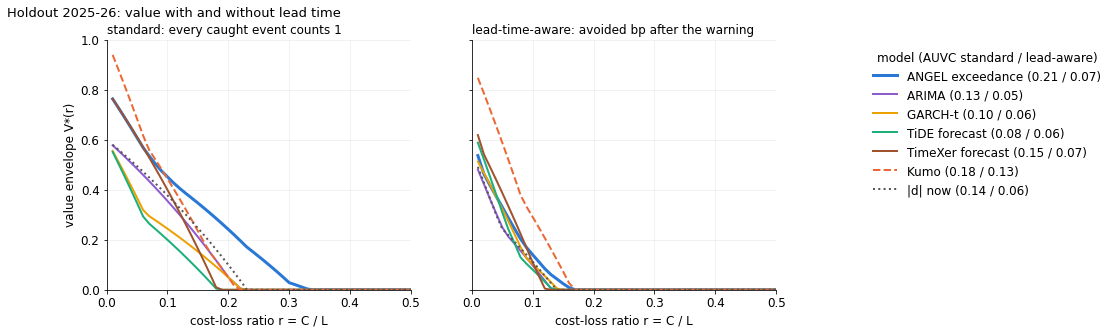

,AUVC,AUVC_lead
model,,
ANGEL exceedance,0.212,0.070
ARIMA,0.133,0.054
GARCH-t,0.103,0.063
TiDE forecast,0.084,0.062
TimeXer forecast,0.147,0.073
Kumo,0.178,0.128
|d| now,0.145,0.057


In [6]:
SHOW = HO_SHOW + ["|d| now"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, kind, ttl in zip(axes, ("standard", "lead"),
                         ("standard: every caught event counts 1", "lead-time-aware: avoided bp after the warning")):
    for m in SHOW:
        g = hc[hc.model.eq(m) & hc.kind.eq(kind)]
        lab = f"{m} ({hs.loc[m, 'AUVC']:.2f} / {hs.loc[m, 'AUVC_lead']:.2f})"
        ax.plot(g.r, g.V, label=lab if kind == "standard" else None, **STYLE[m])
    ax.set_xlim(0, 0.5); ax.set_ylim(0, 1); ax.set_title(ttl, loc="left", fontsize=12)
    ax.set_xlabel("cost-loss ratio r = C / L")
axes[0].set_ylabel("value envelope V*(r)")
fig.legend(title="model (AUVC standard / lead-aware)", loc="upper left", bbox_to_anchor=(1.0, 0.88))
fig.suptitle("Holdout 2025-26: value with and without lead time", x=0.01, ha="left", fontsize=13)
save(fig, "05_holdout_lead_time_value")
hs.loc[SHOW, ["AUVC", "AUVC_lead"]].round(3)

Where do the warnings land? Each panel is one holdout event (|d| in bp, hours relative to onset); a marker is the
first timely alert of each score, at the cutoff that maximises V(0.1) on the holdout (ex post, same rule for all).

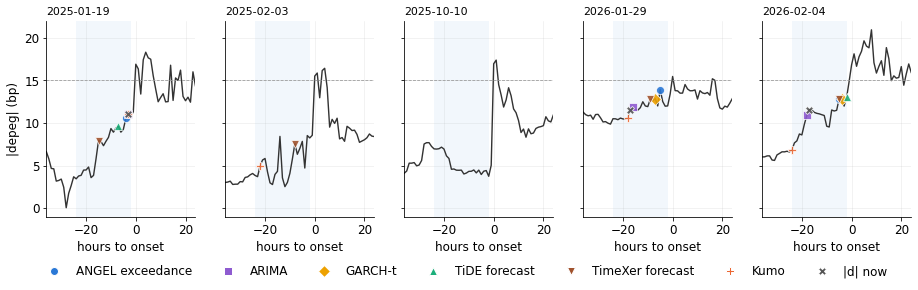

,detected,lead_hours,d_at_alert,avoided_bp,false_alerts_per_month,V_0p1
model,,,,,,
ANGEL exceedance,0.6,4.67,12.45,5.79,0.39,0.47
ARIMA,0.6,12.33,11.26,6.98,0.71,0.36
GARCH-t,0.4,5.50,12.85,5.35,0.45,0.24
Kumo,0.8,16.75,8.36,9.43,1.03,0.44
TiDE forecast,0.4,4.50,11.30,8.33,0.58,0.20
TimeXer forecast,0.8,9.25,10.28,7.51,1.16,0.40
|d| now,0.6,12.33,11.38,6.86,0.64,0.38


In [7]:
paths = pd.read_csv(DATA / "holdout_event_paths.csv"); al = pd.read_csv(DATA / "holdout_event_alerts.csv")
ev = list(dict.fromkeys(paths.event_time))
fig, axes = plt.subplots(1, len(ev), figsize=(3.1 * len(ev), 3.6), sharey=True)
MARK = dict(zip(SHOW, "osD^vPX"))
for ax, e in zip(axes, ev):
    p = paths[paths.event_time.eq(e)]
    ax.plot(p.hours, p.depeg_bps.abs(), color="#333333", lw=1.4)
    ax.axhline(15, color="#999999", lw=0.8, ls="--"); ax.axvspan(-24, -2, color="#2a78d6", alpha=0.06, lw=0)
    a = al[al.event_time.eq(e) & al.detected.eq(1)]
    for m in SHOW:
        row = a[a.model.eq(m)]
        if len(row):
            ax.plot(-row.lead_hours, row.d_at_alert, marker=MARK[m], ls="none", ms=8, color=STYLE[m]["color"],
                    mec="white", mew=0.8, label=m, alpha=0.9)
    ax.set_title(pd.Timestamp(e).strftime("%Y-%m-%d"), fontsize=11, loc="left"); ax.set_xlim(-36, 24)
    ax.set_xlabel("hours to onset")
axes[0].set_ylabel("|depeg| (bp)")
from matplotlib.lines import Line2D
h = [Line2D([], [], marker=MARK[m], ls="none", ms=8, color=STYLE[m]["color"], mec="white") for m in SHOW]
l = SHOW
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=len(l))
save(fig, "06_holdout_alert_timing")
al.groupby("model")[["detected", "lead_hours", "d_at_alert", "avoided_bp", "false_alerts_per_month", "V_0p1"]].mean().round(2)

## Take-aways

* Reading warnings off the probabilistic forecast beats training a classifier on the rare label: in CV every
  forecast-derived ANGEL/ARIMA score is above every direct classifier, and the same architecture trained as a
  classifier (ANGEL classifier, dashed) loses most of the value of ANGEL exceedance.
* In CV ANGEL exceedance and ARIMA are level (fold-to-fold ranges overlap); on the untouched holdout ANGEL has the
  highest value of all scores, ahead of the classifier (Kumo) and of the benchmark forecasts.
* Lead time: with only 5 holdout events the lead-aware value mainly shows the cost of late warnings (ANGEL alerts at
  ~4-5 h lead when |d| is already ~12 bp); it is a caveat on the simple cost-loss model, not a ranking.